# Brain Tumor MRI Classification: DINOv3 + PCA + Grad-CAM
**Pipeline:** Import → Preprocess (224×224, normalize, augment non-square) → DINOv3 features → PCA → classifier → metrics/ROC → Grad-CAM

Set the runtime to **GPU** (Runtime → Change runtime type → T4 GPU).

## 1) Import

In [1]:
!pip install -q "transformers>=4.56" grad-cam scikit-learn seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 435.8 kB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, glob, random, zipfile, numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from PIL import Image
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_curve, auc)
from sklearn.preprocessing import label_binarize

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [4]:
# Upload the Kaggle zip (archive.zip) from your computer
from google.colab import files
up = files.upload()
zip_name = list(up.keys())[0]

os.makedirs("/content/data", exist_ok=True)
with zipfile.ZipFile(zip_name) as z:
    z.extractall("/content/data")

# Locate Training / Testing folders
train_dir = test_dir = None
for root, dirs, _ in os.walk("/content/data"):
    for d in dirs:
        if d.lower() == "training": train_dir = os.path.join(root, d)
        if d.lower() == "testing":  test_dir  = os.path.join(root, d)
print(train_dir, test_dir)

Saving archive (2).zip to archive (2).zip
/content/data/Training /content/data/Testing


## 2) Preprocessing: resize to 224×224, normalize, augment non-square images

In [13]:
IMG = 224
classes = sorted(os.listdir(train_dir))
class_to_idx = {c: i for i, c in enumerate(classes)}
print("Classes:", classes)

def list_items(root):
    items = []
    for c in classes:
        for p in glob.glob(os.path.join(root, c, "*")):
            if p.lower().endswith((".jpg", ".jpeg", ".png")):
                items.append((p, class_to_idx[c]))
    return items

train_items, test_items = list_items(train_dir), list_items(test_dir)

# Check which images are NOT square (rows != columns)
def is_square(p):
    w, h = Image.open(p).size
    return w == h
nonsq_train = [not is_square(p) for p, _ in train_items]
print(f"Train images: {len(train_items)} | non-square: {sum(nonsq_train)}")
print(f"Test images : {len(test_items)}")

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Train images: 5600 | non-square: 1090
Test images : 1600


In [14]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats (used by DINOv3)

base_tf = T.Compose([T.Resize((IMG, IMG)), T.ToTensor(), T.Normalize(MEAN, STD)])
aug_tf  = T.Compose([T.Resize((IMG, IMG)),
                     T.RandomHorizontalFlip(),
                     T.RandomRotation(15),
                     T.ColorJitter(brightness=0.2, contrast=0.2),
                     T.ToTensor(), T.Normalize(MEAN, STD)])

# Training list: every image once; non-square images get one extra augmented copy
train_list = [(p, y, False) for p, y in train_items]
train_list += [(p, y, True) for (p, y), ns in zip(train_items, nonsq_train) if ns]
test_list  = [(p, y, False) for p, y in test_items]
print("Training samples after augmentation:", len(train_list))

class MRIDataset(Dataset):
    def __init__(self, items): self.items = items
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        p, y, aug = self.items[i]
        img = Image.open(p).convert("RGB")
        return (aug_tf if aug else base_tf)(img), y

train_loader = DataLoader(MRIDataset(train_list), batch_size=64, num_workers=2)
test_loader  = DataLoader(MRIDataset(test_list),  batch_size=64, num_workers=2)

Training samples after augmentation: 6690


## 3) DINOv3 backbone + feature extraction

In [15]:
from transformers import AutoModel
MODEL_ID = "facebook/dinov3-vits16-pretrain-lvd1689m"   # small & fast; ViT-B: facebook/dinov3-vitb16-pretrain-lvd1689m
backbone = AutoModel.from_pretrained(MODEL_ID).to(device).eval()
NREG  = getattr(backbone.config, "num_register_tokens", 0)
PATCH = backbone.config.patch_size
GRID  = IMG // PATCH
print("Hidden size:", backbone.config.hidden_size, "| register tokens:", NREG, "| grid:", GRID)

def pooled(h):
    # CLS token + mean of patch tokens  -> feature vector
    return torch.cat([h[:, 0], h[:, 1 + NREG:].mean(1)], dim=1)

@torch.no_grad()
def extract(loader):
    F, Y = [], []
    for x, y in loader:
        h = backbone(pixel_values=x.to(device)).last_hidden_state
        F.append(pooled(h).cpu()); Y.append(y)
    return torch.cat(F).numpy(), torch.cat(Y).numpy()

Xtr, ytr = extract(train_loader)
Xte, yte = extract(test_loader)
print(Xtr.shape, Xte.shape)

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Hidden size: 384 | register tokens: 4 | grid: 14
(6690, 768) (1600, 768)


## 4) Feature reduction with PCA

Feature dim: 768 -> 169 PCA components


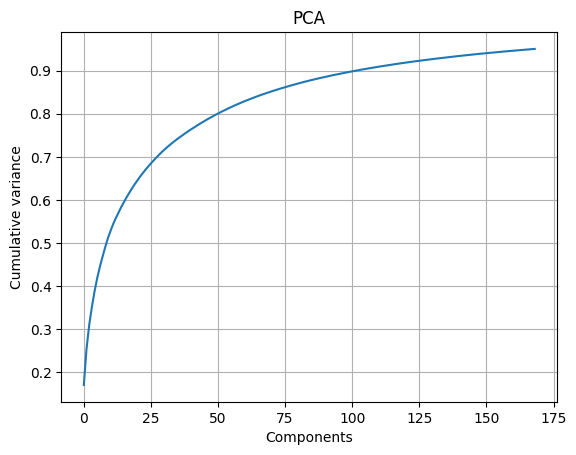

In [16]:
pca = PCA(n_components=0.95, random_state=SEED)      # keep 95% variance
Ztr = pca.fit_transform(Xtr)                         # fit on TRAIN only
Zte = pca.transform(Xte)
print("Feature dim:", Xtr.shape[1], "->", Ztr.shape[1], "PCA components")

plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel("Components"); plt.ylabel("Cumulative variance"); plt.title("PCA"); plt.grid(); plt.show()

## 5) Classifier on PCA features (trained as a torch layer so Grad-CAM can flow end-to-end)

In [17]:
z_std = Ztr.std(0, keepdims=True) + 1e-6
Ztr_t = torch.tensor(Ztr / z_std, dtype=torch.float32).to(device)
Zte_t = torch.tensor(Zte / z_std, dtype=torch.float32).to(device)
ytr_t = torch.tensor(ytr).to(device)

head = nn.Sequential(nn.Dropout(0.2), nn.Linear(Ztr.shape[1], len(classes))).to(device)
opt = torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-2)
lossf = nn.CrossEntropyLoss()

for ep in range(300):
    head.train()
    perm = torch.randperm(len(Ztr_t), device=device)
    for i in range(0, len(perm), 512):
        idx = perm[i:i+512]
        opt.zero_grad(); loss = lossf(head(Ztr_t[idx]), ytr_t[idx]); loss.backward(); opt.step()
    if ep % 50 == 0: print(f"epoch {ep:3d}  loss {loss.item():.4f}")

head.eval()
with torch.no_grad():
    probs = torch.softmax(head(Zte_t), 1).cpu().numpy()
pred = probs.argmax(1)

epoch   0  loss 1.4722
epoch  50  loss 0.4176
epoch 100  loss 0.2787
epoch 150  loss 0.2919
epoch 200  loss 0.2925
epoch 250  loss 0.4090


## 6) Results: accuracy, precision, recall, F1, ROC curve

Accuracy : 0.8962
Precision: 0.9016  (macro)
Recall   : 0.8962  (macro)
F1-score : 0.8940  (macro)

              precision    recall  f1-score   support

      glioma     0.9544    0.7325    0.8289       400
  meningioma     0.8111    0.8800    0.8441       400
     notumor     0.8825    0.9950    0.9354       400
   pituitary     0.9583    0.9775    0.9678       400

    accuracy                         0.8962      1600
   macro avg     0.9016    0.8962    0.8940      1600
weighted avg     0.9016    0.8962    0.8940      1600



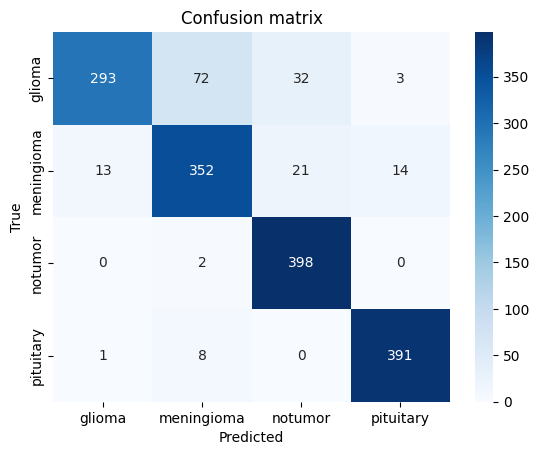

In [18]:
print(f"Accuracy : {accuracy_score(yte, pred):.4f}")
print(f"Precision: {precision_score(yte, pred, average='macro'):.4f}  (macro)")
print(f"Recall   : {recall_score(yte, pred, average='macro'):.4f}  (macro)")
print(f"F1-score : {f1_score(yte, pred, average='macro'):.4f}  (macro)\n")
print(classification_report(yte, pred, target_names=classes, digits=4))

cm = confusion_matrix(yte, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix"); plt.show()

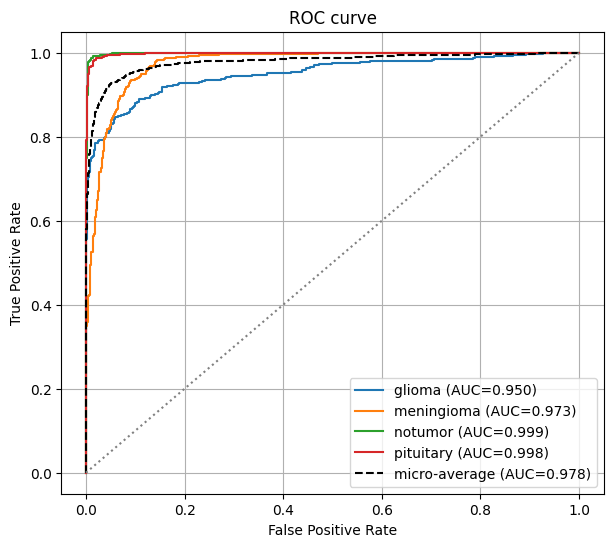

In [19]:
# ROC curve (one-vs-rest for each class + micro average)
Y = label_binarize(yte, classes=range(len(classes)))
plt.figure(figsize=(7, 6))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(Y[:, i], probs[:, i])
    plt.plot(fpr, tpr, label=f"{c} (AUC={auc(fpr, tpr):.3f})")
fpr, tpr, _ = roc_curve(Y.ravel(), probs.ravel())
plt.plot(fpr, tpr, "k--", label=f"micro-average (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "gray", ls=":")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curve"); plt.legend(loc="lower right"); plt.grid(); plt.show()

## 7) Explainable AI: Grad-CAM

Last block contains: ['norm1', 'attention', 'layer_scale1', 'drop_path', 'norm2', 'mlp', 'layer_scale2']


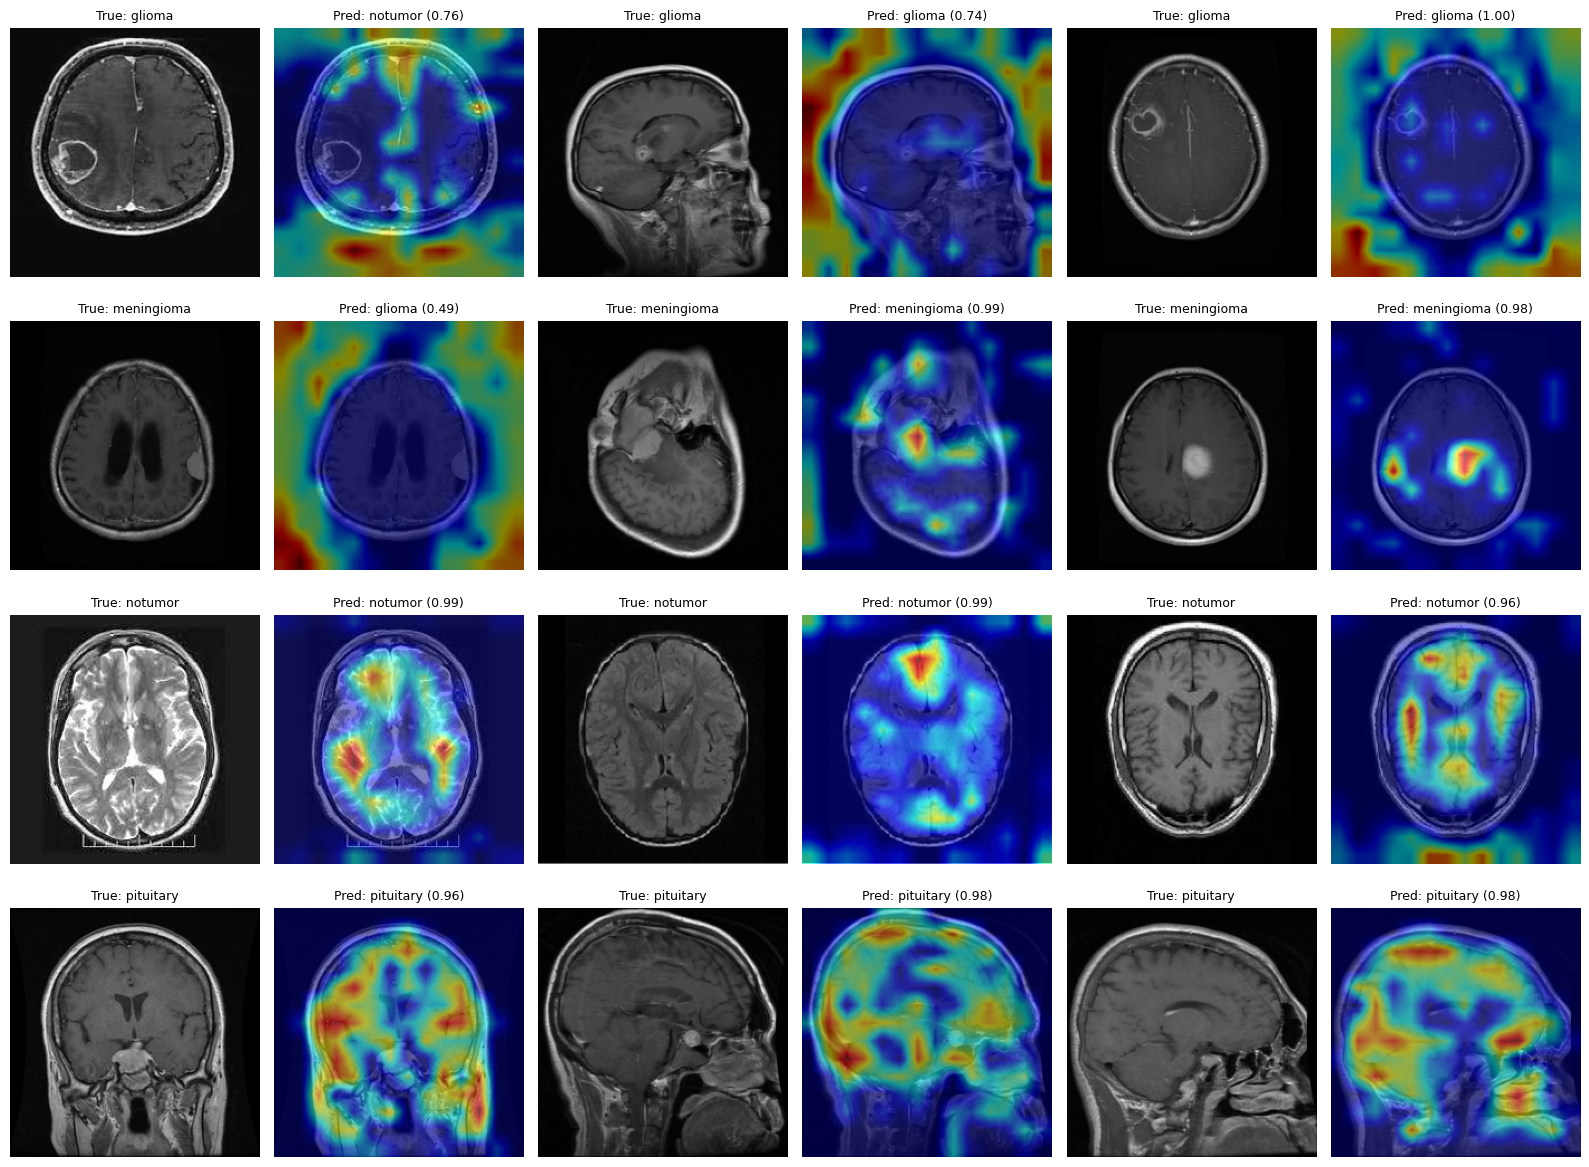

In [21]:
# Full differentiable model: DINOv3 -> pooled feature -> PCA (linear) -> classifier
class FullModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = backbone
        self.register_buffer("mean",  torch.tensor(pca.mean_, dtype=torch.float32))
        self.register_buffer("comps", torch.tensor(pca.components_, dtype=torch.float32))
        self.register_buffer("zstd",  torch.tensor(z_std, dtype=torch.float32))
        self.head = head
    def forward(self, x):
        f = pooled(self.backbone(pixel_values=x).last_hidden_state)
        z = ((f - self.mean) @ self.comps.T) / self.zstd
        return self.head(z)

full = FullModel().to(device).eval()

def reshape_transform(t):
    # (B, 1+NREG+N, C) -> drop CLS/register tokens -> (B, C, GRID, GRID)
    t = t[:, 1 + NREG:, :]
    t = t.reshape(t.size(0), GRID, GRID, t.size(2))
    return t.permute(0, 3, 1, 2)

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Find the list of transformer blocks automatically
blocks = [m for n, m in backbone.named_modules()
          if isinstance(m, nn.ModuleList) and len(m) == backbone.config.num_hidden_layers][0]
last = blocks[-1]
print("Last block contains:", [n for n, _ in last.named_children()])

# First LayerNorm of the last block (norm1 if it exists)
target_layer = last.norm1 if hasattr(last, "norm1") else \
               [m for m in last.modules() if isinstance(m, nn.LayerNorm)][0]
cam = GradCAM(model=full, target_layers=[target_layer], reshape_transform=reshape_transform)

def explain(path, true_label):
    img = Image.open(path).convert("RGB")
    rgb = np.array(img.resize((IMG, IMG))).astype(np.float32) / 255
    x = base_tf(img).unsqueeze(0).to(device)
    with torch.no_grad(): p = torch.softmax(full(x), 1)[0]
    k = int(p.argmax())
    heat = cam(input_tensor=x, targets=[ClassifierOutputTarget(k)])[0]
    return rgb, show_cam_on_image(rgb, heat, use_rgb=True), classes[k], float(p[k])

# 3 random test images from each class
fig, axs = plt.subplots(len(classes), 6, figsize=(16, 3 * len(classes)))
for r, c in enumerate(classes):
    paths = random.sample([p for p, y in test_items if y == class_to_idx[c]], 3)
    for j, p in enumerate(paths):
        rgb, overlay, pc, conf = explain(p, c)
        axs[r, 2*j].imshow(rgb);     axs[r, 2*j].set_title(f"True: {c}", fontsize=9)
        axs[r, 2*j+1].imshow(overlay); axs[r, 2*j+1].set_title(f"Pred: {pc} ({conf:.2f})", fontsize=9)
for a in axs.ravel(): a.axis("off")
plt.tight_layout(); plt.show()